# Preparação dos dados e análise exploratória

Apartamentos à venda em Passo Fundo, coletados em um portal imobiliário regional em 23/08/2026. Aqui é feito o pré-processamento, o cálculo das distâncias aos pontos de interesse e a análise exploratória do artigo.

As funções ficam na pasta `analise/` e são chamadas passo a passo. No Colab, envie o arquivo `notebooks/projeto_colab.zip` quando a primeira célula pedir (arquivos soltos não funcionam, porque o Colab perde as pastas).

## Configuração

In [1]:
import sys
import zipfile
from pathlib import Path

# acha a pasta do projeto (no Colab ela vem do projeto_colab.zip)
def achar_projeto():
    for pasta in [Path.cwd(), Path.cwd().parent, Path("/content/projeto")]:
        if (pasta / "dados" / "dataset_bruto.csv").exists():
            return pasta

RAIZ = achar_projeto()
if RAIZ is None:
    from google.colab import files
    enviado = files.upload()  # escolha o arquivo projeto_colab.zip
    with zipfile.ZipFile(next(iter(enviado))) as z:
        z.extractall("/content/projeto")
    RAIZ = achar_projeto()

sys.path.insert(0, str(RAIZ / "analise"))
sys.path.insert(0, str(RAIZ / "scraper"))
print("projeto em", RAIZ)

projeto em C:\Users\richardson.moraes\Documents\TCC - WebScraping\TCC-Precificação-Imobiliaria


In [2]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

import config
import preprocessamento as pp
import features
import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

## Base bruta

Cada linha é um anúncio. A coluna `id` segue a ordem do arquivo e é a mesma usada na planilha de revisão.

In [3]:
bruto = pd.read_csv(pp.ENTRADA, encoding="utf-8-sig")
df = bruto.copy()
df.insert(0, "id", np.arange(1, len(df) + 1))
print(len(df), "anúncios,", bruto.shape[1], "colunas")

# quanto de cada campo veio preenchido
principais = ["preco", "area_util_m2", "dormitorios", "suites", "banheiros", "vagas_garagem",
              "condominio", "bairro", "latitude"]
cobertura = (df[principais].notna().mean() * 100).round(1).rename("preenchido (%)")
cobertura.to_frame()

1219 anúncios, 61 colunas


,preenchido (%)
preco,97.3
area_util_m2,97.9
dormitorios,89.7
suites,55.0
banheiros,88.0
vagas_garagem,85.6
condominio,74.7
bairro,94.3
latitude,80.6


In [4]:
# avisos que o scraper gravou na coleta (problemas do cadastro no portal)
from collections import Counter
alertas = Counter(a.strip() for s in df["alertas_qualidade"].dropna() for a in s.split(";") if a.strip())
pd.Series(alertas, name="anúncios").sort_values(ascending=False).to_frame()

,anúncios
sem_ano,995
sem_geo,237
sem_vagas,175
sem_banheiros,146
preco_a_partir_de,133
sem_dormitorios,126
sem_bairro,70
sem_preco,33
area_total<privativa,24
preco_card!=ficha,18


## Revisão dos anúncios suspeitos

Algumas regras marcaram os anúncios suspeitos: página que não carregou, título de outro tipo de imóvel, sem preço, área estranha, preço por m² fora de R\$ 3.000 a R\$ 20.000 e anúncios com preço, área e dormitórios iguais aos de outro. Cada um foi aberto de novo no portal (o texto das páginas está em `dados/revisao/paginas/`), e a decisão ficou anotada em `dados/revisao/revisao_manual.csv`, com o motivo e a evidência. Nenhum valor foi estimado: as correções usam só o que está no próprio anúncio.

Para as duplicatas: imobiliárias diferentes, mesmo prédio, preço e área iguais, é o mesmo imóvel e fica o anúncio mais completo. Mesma imobiliária com códigos diferentes conta como unidades diferentes, a não ser que a página mostre o contrário.

In [5]:
# decisões por tipo de problema
revisao = pd.read_csv(pp.REVISAO, encoding="utf-8-sig")
pd.crosstab(revisao["categoria"], revisao["decisao"], margins=True, margins_name="total")

decisao,corrigir,excluir,manter,total
categoria,,,,
area_suspeita,0,7,0,7
bairro,4,0,0,4
duplicata,0,26,48,74
falha_carga,0,22,0,22
nao_apartamento,0,17,1,18
preco_m2_suspeito,0,0,16,16
sem_preco,0,9,0,9
total,4,81,65,150


In [6]:
# alguns exemplos, com a evidência anotada
exemplos = revisao[revisao["codigo_imovel"].isin(["V54311", "V54957", "V64242", "V46072", "V28796", "V53792", "V53783"])]
exemplos[["id", "codigo_imovel", "titulo", "decisao", "motivo", "evidencia"]]

,id,codigo_imovel,titulo,decisao,motivo,evidencia
0,6,V54311,ALPEN - VILA RODRIGUES,excluir,área privativa inválida no próprio cadastro do portal,"página: '0,55 m² Área Privativa', '0,14 m² Área Total'"
15,76,V46072,APARTAMENTO TRÊS DORMITÓRIOS | SOLAR PETRÓPOLIS,excluir,"mesmo imóvel do id 77 (outra imobiliária, mesmo prédio, preço e área)",grupo 36
16,77,V28796,ED. SOLAR PETRÓPOLIS- 3 VAGAS- MOBILIADO,manter,mesmo imóvel anunciado por outra imobiliária; mantido por ser o an...,grupo 36
17,79,V64242,CASA MERLOT - 3 DORMITÓRIOS MOBILIADO,manter,falso positivo: é apartamento no Edifício Casa Merlot,"página: 'Lindo apartamento, no Edifício Casa Merlot'"
65,647,V54957,CASA - ARROIO DO SAL,excluir,"casa em outro município (Arroio do Sal), cadastrada como Passo Fundo","página: 'Casa Espaçosa em Vista Alegre, Arroio do Sal'"
113,962,V53792,ED. ESPLANADA I,manter,"unidades distintas: uma 'de frente', outra 'de fundos'",grupo 6
114,963,V53783,ED. ESPLANADA I,manter,"unidades distintas: uma 'de frente', outra 'de fundos'",grupo 6


In [7]:
# aplica as exclusões e conta quantos saíram em cada etapa
funil = pp.Funil(len(df))
df = pp.aplicar_revisao(df, funil)
df = funil.remover(df, df["preco"].isna(), "Sem preço (restantes)")
df = funil.remover(df, df["area_util_m2"].isna(), "Sem área privativa (restantes)")
funil.tabela()

,etapa,removidos,restantes
0,Base bruta (coleta de 23/08/2026),0,1219
1,Revisão manual: anúncio retirado do portal durante a coleta,22,1197
2,"Revisão manual: não é apartamento (box, casa, imóvel misto)",17,1180
3,Revisão manual: sem preço publicado,9,1171
4,Revisão manual: área privativa inválida ou não publicada,7,1164
5,Revisão manual: mesmo imóvel anunciado por outra imobiliária,26,1138
6,Sem preço (restantes),0,1138
7,Sem área privativa (restantes),0,1138


As duas últimas linhas ficaram zeradas, então a revisão pegou todos os anúncios sem preço ou sem área.

In [8]:
# números da seção 4.1 do artigo
print("imobiliárias:", bruto["imobiliaria_origem"].nunique())

# o que eram os anúncios que não são apartamento
nao_apto = revisao[(revisao["categoria"] == "nao_apartamento") & (revisao["decisao"] == "excluir")]
tipo = np.select([nao_apto["motivo"].str.contains("box"), nao_apto["motivo"].str.contains("misto")],
                 ["box de garagem", "imóvel misto"], "casa")
print("não são apartamento:", pd.Series(tipo).value_counts().to_dict())

# páginas que não carregaram na coleta
falhas = revisao[revisao["categoria"] == "falha_carga"]
print("não carregaram:", len(falhas),
      "| retiradas do portal:", (falhas["pagina_em_05_10"] == "removida").sum(),
      "| não era anúncio:", falhas["motivo"].str.contains("não é anúncio").sum())

# anúncios coletados normalmente e reabertos na revisão (05/10): quantos já tinham saído do portal
coletados = revisao[revisao["categoria"] != "falha_carga"].drop_duplicates("id")
abertos = coletados[coletados["pagina_em_05_10"] != "nao_aberta"]
print("reabertos na revisão:", len(abertos), "| já retirados:", (abertos["pagina_em_05_10"] == "removida").sum())

imobiliárias: 14
não são apartamento: {'box de garagem': 10, 'casa': 5, 'imóvel misto': 2}
não carregaram: 22 | retiradas do portal: 21 | não era anúncio: 1
reabertos na revisão: 122 | já retirados: 12


## Correções por regra

Valem para todos os anúncios que sobraram e usam só informação do próprio anúncio:

| Campo | Regra |
|---|---|
| Condomínio | até R\$ 1 é preenchimento do portal, então vira vazio |
| Suítes | a ficha só mostra suítes quando existem, então vazio = 0 (ou 1, se a lista de características cita "Suíte") |
| Lavabos e elevadores | mesma ideia, vazio = 0 (elevador só se a lista também não cita) |
| Vagas e banheiros | tirados da lista de características ("Garagem p/ 2 Carros", "Banheiros (2)") |
| Dormitórios | tirados do título ("TRÊS DORMITÓRIOS"); até 45 m² sem dormitório é studio (0) |
| Mobília | tirada do campo `propriedades_extras` |

In [9]:
# quantos vazios cada regra preencheu (no condomínio fica negativo porque os valores até R$ 1 viram vazio)
campos = ["condominio", "suites", "lavabos", "elevadores", "vagas_garagem", "banheiros", "dormitorios"]
antes = df[campos].isna().sum()
df = pp.corrigir_valores(df)
depois = df[campos].isna().sum()
pd.DataFrame({"vazios antes": antes, "vazios depois": depois, "preenchidos": antes - depois})

,vazios antes,vazios depois,preenchidos
condominio,261,304,-43
suites,502,4,498
lavabos,861,0,861
elevadores,214,74,140
vagas_garagem,147,140,7
banheiros,109,88,21
dormitorios,90,6,84


In [10]:
# conferindo a regra das suítes: sem suíte o preço é bem menor
df.groupby("suites")["preco"].median().map("R$ {:,.0f}".format).to_frame("preço mediano")

,preço mediano
suites,
0.0,"R$ 360,000"
1.0,"R$ 750,000"
2.0,"R$ 850,000"
3.0,"R$ 1,900,000"
4.0,"R$ 3,700,000"


## Bairro, coordenadas e variáveis derivadas

- Bairro: nomes padronizados (maiúsculas, acentos, prefixo "Bairro"). Quando falta, usa o bairro mais comum entre os 5 anúncios mais próximos (`bairro_inferido = 1`).
- Coordenadas: quando faltam, usa a mediana das coordenadas dos anúncios do bairro, se o bairro tiver pelo menos 3 anúncios com coordenada (`geo_imputada = 1`). Essas duas marcas servem só para conferência e não entram nos modelos.
- Derivadas: `preco_lancamento` (rótulo "A partir de"), `na_planta`, `preco_m2` e `dias_anunciado`.

In [11]:
n_bairros_antes = df["bairro"].nunique()
df = pp.padronizar_bairro(df, bruto)
df = pp.imputar_coordenadas(df)
df = pp.derivar(df)
print("grafias de bairro:", n_bairros_antes, "->", df["bairro"].nunique())
print("bairro inferido:", df["bairro_inferido"].sum(), "| ainda sem bairro:", df["bairro"].isna().sum())
print("coordenada imputada:", df["geo_imputada"].sum(), "| ainda sem coordenada:", df["latitude"].isna().sum())
print("'A partir de':", df["preco_lancamento"].sum())

grafias de bairro: 45 -> 38
bairro inferido: 33 | ainda sem bairro: 9
coordenada imputada: 182 | ainda sem coordenada: 14
'A partir de': 128


Colunas descartadas: `preco_card`, `preco_anterior`, `variacao_preco_pct` e `teve_reducao_preco` vêm do próprio preço; `n_caracteres_html` não tem a ver com o imóvel; `andar` e `comodos` vêm vazios do portal; `ano_construcao` e `iptu` faltam em mais de 80% dos anúncios.

In [12]:
df = df.drop(columns=[c for c in pp.DESCARTAR if c in df.columns])
print("base limpa:", df.shape[0], "anúncios,", df.shape[1], "colunas")

base limpa: 1138 anúncios, 37 colunas


## Conferência com os scripts

In [13]:
# tem que dar exatamente o arquivo gerado pelo preprocessamento.py
limpo = pd.read_csv(pp.SAIDA, encoding="utf-8-sig")
pd.testing.assert_frame_equal(df.reset_index(drop=True), limpo, check_dtype=False)
print("igual ao dados/dataset_limpo.csv")

igual ao dados/dataset_limpo.csv


O preenchimento dos vazios que sobraram, a normalização e o one-hot não são feitos aqui. Eles dependem dos dados, então são ajustados só no treino, dentro do pipeline do notebook 02 (mediana nas numéricas, com uma coluna marcando o vazio, e categoria `nao_informado` nas categóricas).

In [14]:
ausentes = df.isna().sum()
ausentes[ausentes > 0].sort_values(ascending=False).to_frame("vazios")

,vazios
posicao_solar,724
condominio,304
vagas_garagem,140
posicao,135
banheiros,88
elevadores,74
latitude,14
longitude,14
bairro,9
dormitorios,6


## Distâncias aos pontos de interesse

Distância de Haversine até o ponto mais próximo de cada categoria. As coordenadas dos pontos são do OpenStreetMap (05/10/2026).

In [15]:
pois = pd.DataFrame([(cat, nome, lat, lon) for cat, pts in config.PONTOS_INTERESSE.items()
                     for nome, (lat, lon) in pts.items()],
                    columns=["categoria", "ponto de interesse", "latitude", "longitude"])
pois

,categoria,ponto de interesse,latitude,longitude
0,shopping,Passo Fundo Shopping,-28.271000,-52.385462
1,shopping,Bella Citta,-28.262744,-52.409594
2,hospital,Sao Vicente de Paulo,-28.262317,-52.417013
3,hospital,Hospital de Clinicas,-28.256247,-52.403069
4,hospital,Hospital Municipal,-28.258489,-52.393858
5,ensino,UPF,-28.234533,-52.378616
6,ensino,Atitus Educacao,-28.265197,-52.397109
7,ensino,Anhanguera,-28.260201,-52.408324
8,ensino,Colegio Notre Dame,-28.264629,-52.412975
9,ensino,Colegio Marista,-28.258119,-52.406104


In [16]:
# distância ao ponto mais próximo de cada categoria
for categoria, pontos in config.PONTOS_INTERESSE.items():
    dist = np.column_stack([features.haversine_km(df["latitude"], df["longitude"], lat, lon)
                            for lat, lon in pontos.values()])
    df[f"dist_{categoria}_km"] = np.round(dist.min(axis=1), 3)

# tem que dar exatamente o arquivo gerado pelo features.py
modelagem = pd.read_csv(features.SAIDA, encoding="utf-8-sig")
pd.testing.assert_frame_equal(df.reset_index(drop=True), modelagem, check_dtype=False)
print("igual ao dados/dataset_modelagem.csv")
df[[c for c in df.columns if c.startswith("dist_")]].describe().round(2)

igual ao dados/dataset_modelagem.csv


,dist_shopping_km,dist_hospital_km,dist_ensino_km
count,1124.00,1124.00,1124.00
mean,1.13,1.02,0.87
std,0.90,0.77,0.75
min,0.05,0.09,0.05
25%,0.46,0.54,0.32
50%,0.91,0.72,0.57
75%,1.37,1.39,1.20
max,4.53,4.58,4.39


## Análise exploratória

As figuras são as mesmas do artigo e ficam salvas em `saidas/figuras/`. As correlações são de Spearman, que não supõe relação linear e lida melhor com a assimetria dos preços.

In [17]:
# mostra a figura salva
def mostrar(nome):
    display(Image(filename=str(eda.FIG / f"{nome}.png"), width=560))

In [18]:
# gera a tabela descritiva do artigo (tabelas/descritiva.tex)
eda.tabela_descritiva(df)
colunas = {"preco": "Preço (R$)", "preco_m2": "Preço/m² (R$)", "area_util_m2": "Área privativa (m²)",
           "dormitorios": "Dormitórios", "suites": "Suítes", "banheiros": "Banheiros",
           "vagas_garagem": "Vagas", "condominio": "Condomínio (R$/mês)"}
df[list(colunas)].describe().T.rename(index=colunas)[["count", "mean", "50%", "std", "min", "max"]].round(1)

,count,mean,50%,std,min,max
Preço (R$),1138.0,750674.2,590000.0,588889.0,159000.0,5480000.0
Preço/m² (R$),1138.0,8929.6,8641.5,3303.6,2712.9,23405.9
Área privativa (m²),1138.0,85.2,70.7,53.6,22.4,428.4
Dormitórios,1132.0,2.0,2.0,0.9,0.0,6.0
Suítes,1134.0,0.8,1.0,0.9,0.0,4.0
Banheiros,1050.0,1.6,1.0,0.8,1.0,5.0
Vagas,998.0,1.4,1.0,0.6,1.0,5.0
Condomínio (R$/mês),834.0,459.4,350.0,346.3,10.0,2800.0


### Distribuição do preço

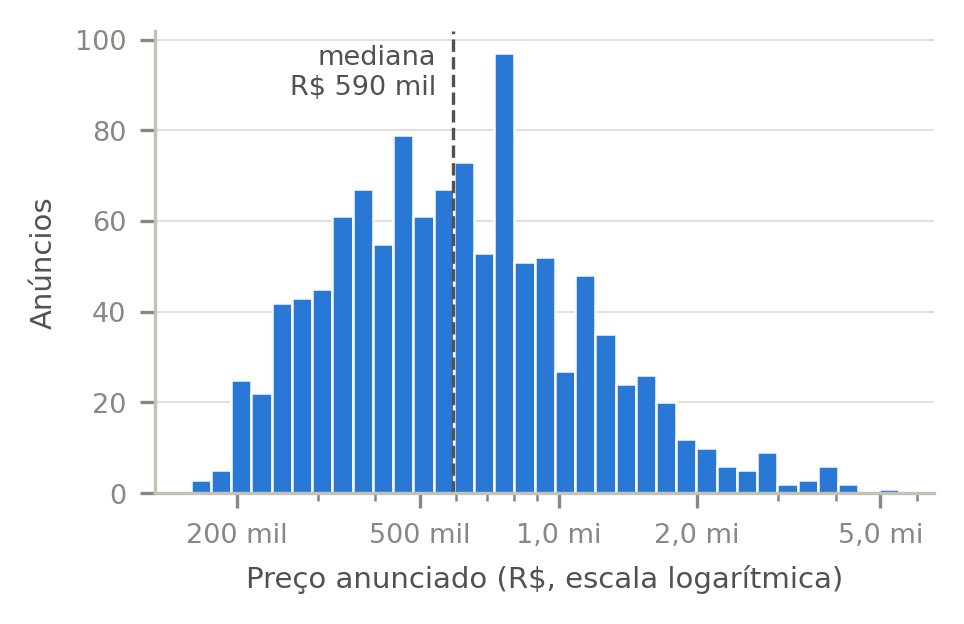

assimetria do preço: 2.77 | do log(preço): 0.45


In [19]:
eda.fig_distribuicao_preco(df)
mostrar("distribuicao_preco")
print(f"assimetria do preço: {df['preco'].skew():.2f} | do log(preço): {np.log(df['preco']).skew():.2f}")

O preço é bem assimétrico à direita e fica quase simétrico no log. Por isso os modelos aprendem o log do preço, e as previsões voltam para reais antes de calcular as métricas.

### Área e tipo de preço

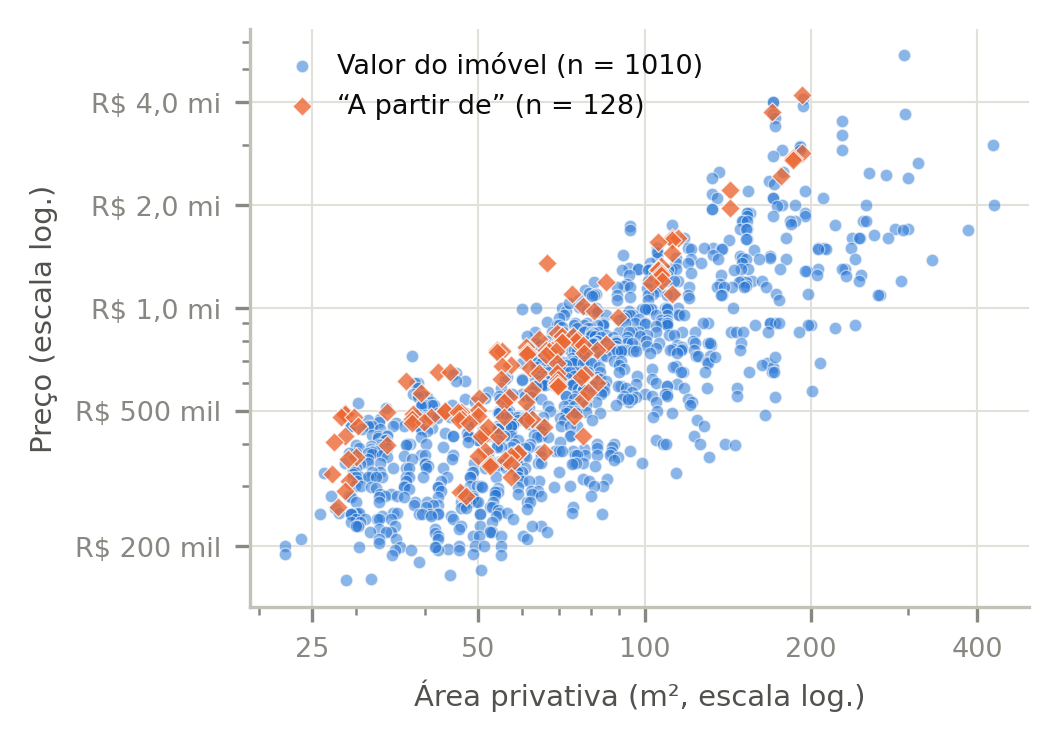

,preço/m² mediano
preco_lancamento,
Valor do imóvel,"R$ 8,417"
A partir de,"R$ 11,154"


In [20]:
eda.fig_preco_area(df)
mostrar("preco_area")
df.groupby("preco_lancamento")["preco_m2"].median().rename({0: "Valor do imóvel", 1: "A partir de"}).map("R$ {:,.0f}".format).to_frame("preço/m² mediano")

A área é o que mais explica o preço, com relação quase linear no gráfico em log. Os anúncios "A partir de" ficam nas áreas menores e têm preço/m² mediano uns 32% maior. Como são preço de tabela de lançamento, e não de uma unidade, ficaram fora da base principal e só entram na análise de sensibilidade do notebook 02.

### Correlação com o preço

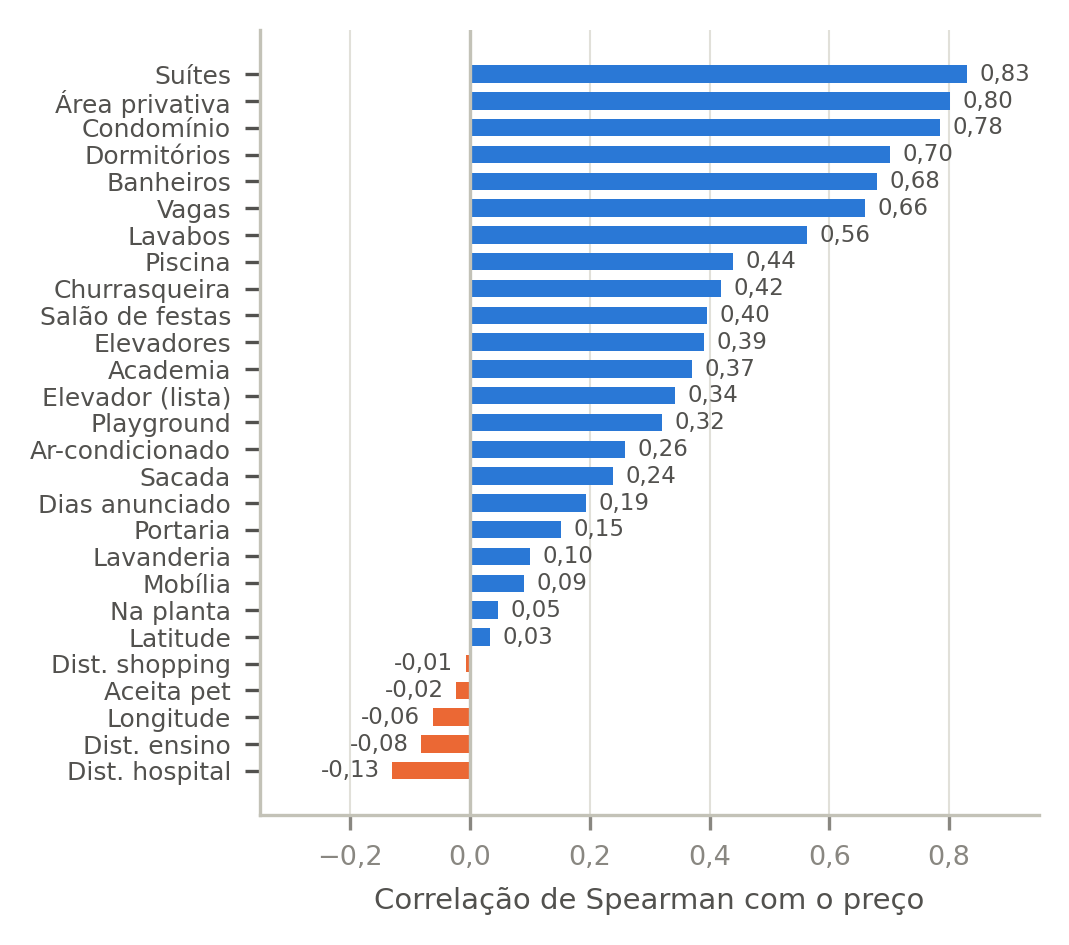

In [21]:
corr = eda.fig_correlacoes(df)
mostrar("correlacao_preco")

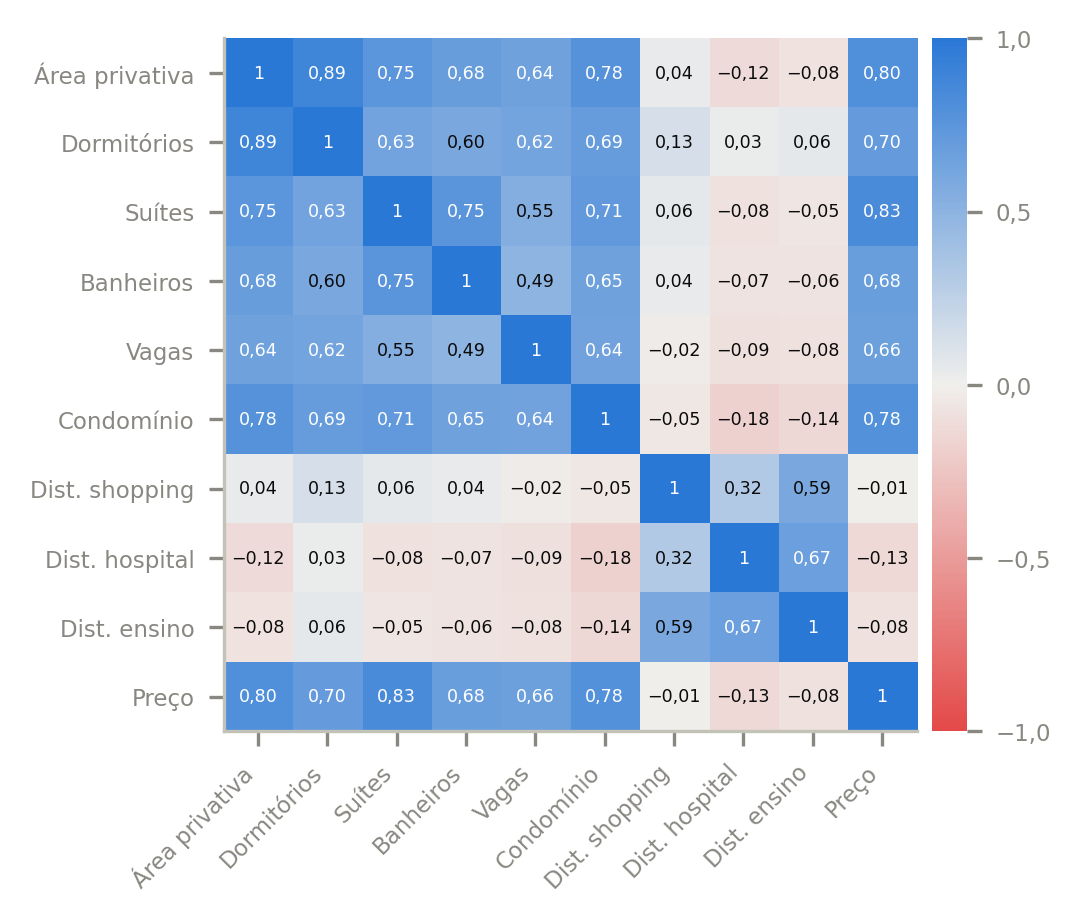

In [22]:
eda.fig_matriz_correlacao(df)
mostrar("matriz_correlacao")

Suítes, área, condomínio, dormitórios, banheiros e vagas têm as correlações mais fortes. Piscina e churrasqueira têm correlação moderada, parecido com o que Reza et al. (2025) encontraram em Chapecó. Área e dormitórios andam muito juntos (0,89), o que atrapalha a leitura dos coeficientes da Regressão Linear, mas não a previsão.

### Localização

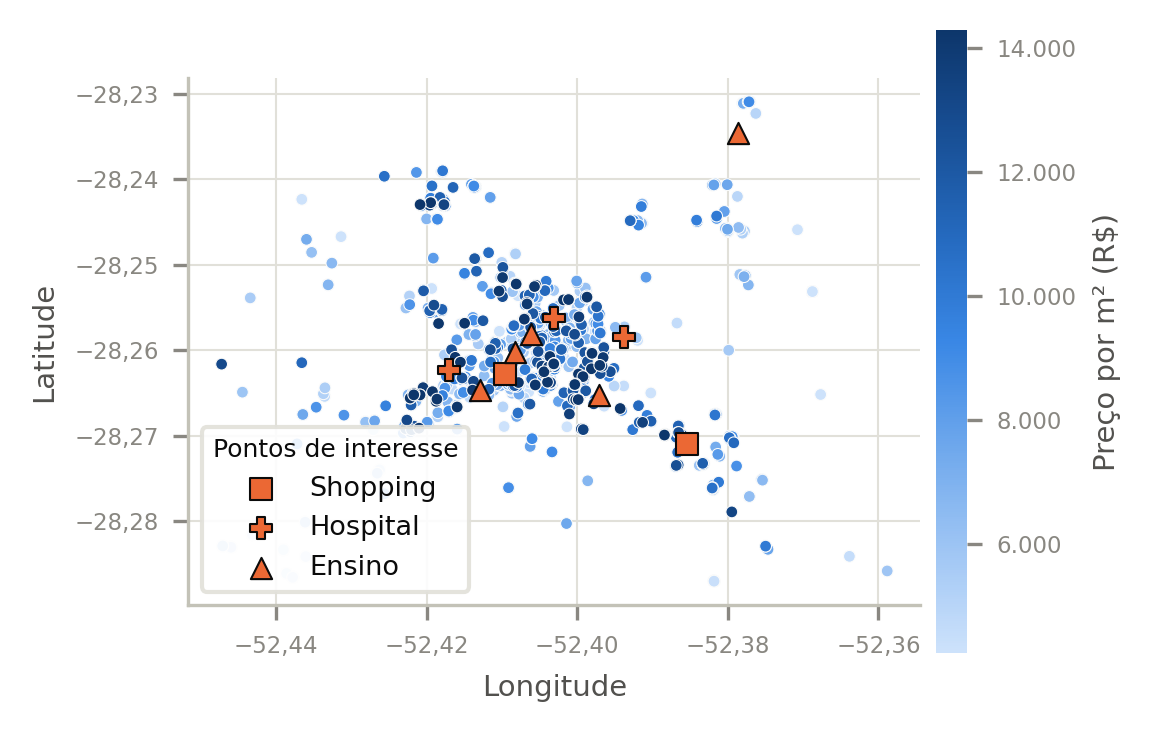

In [23]:
eda.fig_mapa(df)
mostrar("mapa_preco_m2")

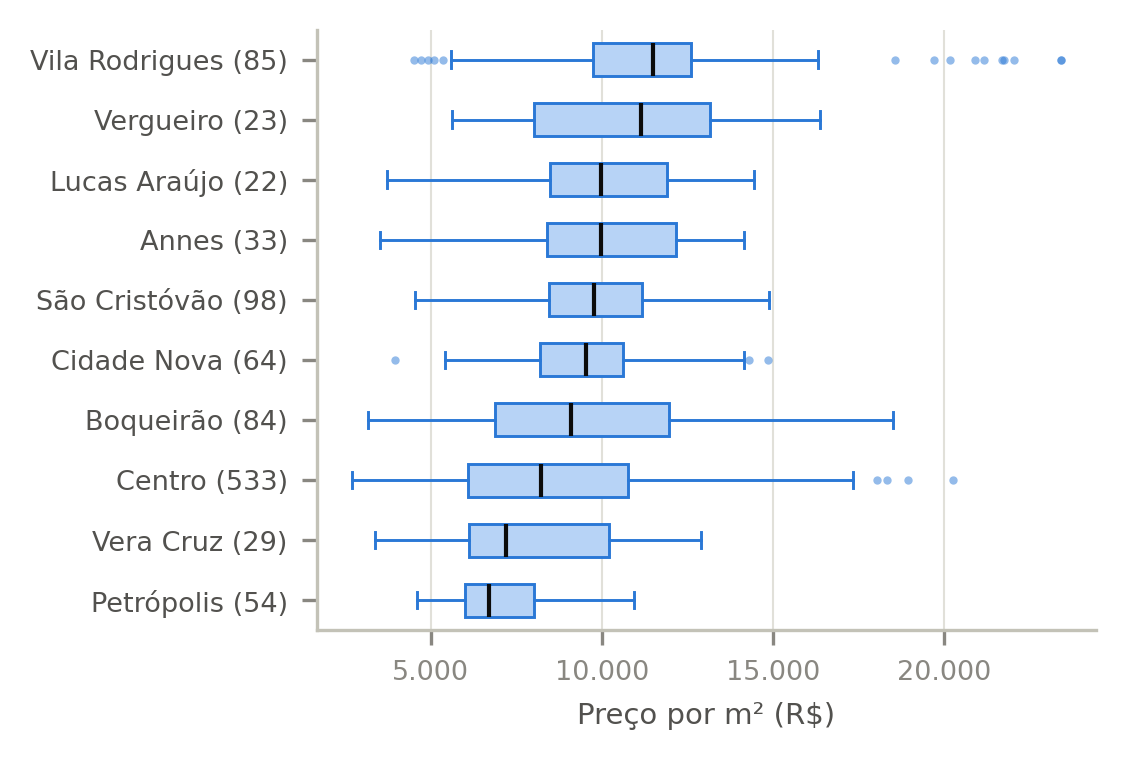

In [24]:
eda.fig_preco_m2_bairro(df)
mostrar("preco_m2_bairro")

In [25]:
dist_cols = [c for c in df.columns if c.startswith("dist_")]
df[dist_cols + ["preco", "preco_m2"]].corr(method="spearman").loc[dist_cols, ["preco", "preco_m2"]].round(3)

,preco,preco_m2
dist_shopping_km,-0.007,-0.076
dist_hospital_km,-0.130,-0.067
dist_ensino_km,-0.081,-0.044


In [26]:
# números da seção 4.2 do artigo
print("distância mediana (km):", df[dist_cols].median().round(2).to_dict())

# bairros com pelo menos 20 anúncios: o mais barato e o mais caro por m²
contagem = df["bairro"].value_counts()
mediana_bairro = df[df["bairro"].isin(contagem[contagem >= 20].index)].groupby("bairro")["preco_m2"].median().sort_values()
print(mediana_bairro.index[0], round(mediana_bairro.iloc[0]), "|", mediana_bairro.index[-1], round(mediana_bairro.iloc[-1]),
      f"| diferença: {mediana_bairro.iloc[-1] / mediana_bairro.iloc[0] - 1:.0%}")

print(f"anúncios no Centro: {df['bairro'].eq('Centro').mean():.0%}")
print("imóveis no mapa (coordenada original):", ((df["geo_imputada"] == 0) & df["latitude"].notna()).sum())

distância mediana (km): {'dist_shopping_km': 0.91, 'dist_hospital_km': 0.72, 'dist_ensino_km': 0.57}
Petrópolis 6698 | Vila Rodrigues 11484 | diferença: 71%
anúncios no Centro: 47%
imóveis no mapa (coordenada original): 942


As distâncias quase não têm relação com o preço (Spearman entre -0,13 e -0,01). Os dez pontos ficam na região central, e metade dos imóveis está a menos de 0,6 km de uma instituição de ensino e a menos de 1 km de um shopping, então essas variáveis mudam pouco de um imóvel para outro. A localização aparece mais entre bairros: o preço/m² mediano vai de R\$ 6.698 em Petrópolis a R\$ 11.484 na Vila Rodrigues, 71% a mais.

A ideia era que bairro e coordenadas representassem a localização melhor que as distâncias. No notebook 02 isso não se confirmou: depois do tamanho e do padrão do imóvel, nenhuma forma de localização acrescenta muito.

## Conclusão

- A base final tem 1.138 anúncios, 128 deles com preço "A partir de".
- O preço é muito assimétrico, então os modelos usam o log do preço.
- O que mais se relaciona com o preço é o tamanho e o padrão do imóvel (suítes, área, condomínio, vagas).
- As distâncias aos pontos de interesse variam pouco e quase não se relacionam com o preço.
- A base `dados/dataset_modelagem.csv` segue para o notebook 02.